In [1]:
"""候選「美國航班延誤 × 實測氣象」的篩選用檢視（notebook 版）。

與 `flights-weather.py` 內容相同，只改為 `# %%` 分格以便轉 notebook：

    jupytext --to notebook scripts/explore/nb_flights_weather.py

僅供判斷此候選是否適合作為選題，非分析結果。
範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、唯一值數、
描述統計、單變數分布、時間序列折線圖。相關係數矩陣另行標註。

不配適任何模型。分組平均只用於確認資料結構是否存在可用的變異，
不構成處理效應估計。
"""

'候選「美國航班延誤 × 實測氣象」的篩選用檢視（notebook 版）。\n\n與 `flights-weather.py` 內容相同，只改為 `# %%` 分格以便轉 notebook：\n\n    jupytext --to notebook scripts/explore/nb_flights_weather.py\n\n僅供判斷此候選是否適合作為選題，非分析結果。\n範圍限於 CLAUDE.md 允許的篩選檢視：筆數、欄位型別、缺失率、唯一值數、\n描述統計、單變數分布、時間序列折線圖。相關係數矩陣另行標註。\n\n不配適任何模型。分組平均只用於確認資料結構是否存在可用的變異，\n不構成處理效應估計。\n'

# 美國航班延誤 × 實測氣象：篩選檢視

資料源：https://www.kaggle.com/datasets/arimancy/observed-weather-us-flights

研究問題：以實際觀測氣象為基準，哪些航空公司、機場與航線系統性地
少報天氣延誤？

檢視使用 24 個月入門檔（1,406 萬列、1.1 GB），schema 與完整版
（4,280 萬列、6.1 GB）相同。

In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import polars as pl

for family in ("Noto Sans CJK TC", "Noto Sans CJK JP", "WenQuanYi Zen Hei"):
    if any(family in f.name for f in matplotlib.font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = family
        break
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

SRC = ROOT / "data" / "raw" / "flights-weather" / "flights_weather_recent_24mo.parquet"
AIRPORTS = ROOT / "data" / "raw" / "flights-weather" / "airports_reference.parquet"
FIGDIR = ROOT / "outputs" / "figures"


def prefix_of(col: str) -> str:
    for p in ("wx_", "oracle_", "reported_"):
        if col.startswith(p):
            return p
    return "(其他)"


lf = pl.scan_parquet(SRC)
schema = lf.collect_schema()
cols = schema.names()

## 1. 規模與欄位

In [3]:
n_rows = lf.select(pl.len()).collect().item()
print(f"列數：{n_rows:,}")
print(f"欄數：{len(cols)}")
print(f"檔案大小：{SRC.stat().st_size / 1e9:.2f} GB")

列數：14,062,629
欄數：211
檔案大小：1.18 GB


## 2. 欄位前綴分布（資料集的洩漏防護設計）

這是這份資料最值得注意的設計：欄位前綴直接標示了能不能安全使用。

- `wx_`：航班資訊截止點**之前**的觀測氣象，預測時可安全使用
- `oracle_`：航班自身事件時刻的氣象，**用於預測即構成洩漏**
- `reported_`：航空公司自報的延誤成因，刻意保留但明確標示不可信

In [4]:
groups: dict[str, list[str]] = {}
for c in cols:
    groups.setdefault(prefix_of(c), []).append(c)

for p, members in sorted(groups.items(), key=lambda kv: -len(kv[1])):
    print(f"\n{p}（{len(members)} 欄）")
    for c in members:
        print(f"  {c:46s} {schema[c]}")


wx_（106 欄）
  wx_origin_temp_c                               Float64
  wx_origin_dewpoint_c                           Float64
  wx_origin_relative_humidity_pct                Float64
  wx_origin_wind_speed_ms                        Float64
  wx_origin_wind_gust_ms                         Float64
  wx_origin_wind_dir_deg                         Float64
  wx_origin_visibility_m                         Float64
  wx_origin_ceiling_m                            Float64
  wx_origin_ceiling_unlimited                    Boolean
  wx_origin_sea_level_pressure_hpa               Float64
  wx_origin_precip_1h_mm                         Float64
  wx_origin_snow_depth_cm                        Float64
  wx_origin_sky_cover_oktas                      Float64
  wx_origin_thunderstorm                         Boolean
  wx_origin_snow                                 Boolean
  wx_origin_freezing_precip                      Boolean
  wx_origin_fog                                  Boolean
  wx_origin_rain   

## 3. 缺失率與唯一值數

唯一值數對 1,400 萬列成本過高，只取類別型欄位。

In [5]:
nulls = lf.select([pl.col(c).null_count().alias(c) for c in cols]).collect().row(0)

cat_cols = [c for c in cols if schema[c] in (pl.Utf8, pl.Categorical, pl.Boolean)]
uniques = lf.select([pl.col(c).n_unique().alias(c) for c in cat_cols]).collect().row(0)
uniq_map = dict(zip(cat_cols, uniques))

print(f"{'欄位':46s} {'缺失率':>9s} {'唯一值':>12s}")
for c, nn in sorted(zip(cols, nulls), key=lambda kv: -kv[1]):
    u = uniq_map.get(c)
    print(f"{c:46s} {nn / n_rows:9.2%} {('' if u is None else f'{u:,}'):>12s}")

欄位                                                   缺失率          唯一值
wx_dest_snow_depth_cm                             99.74%             
wx_origin_snow_depth_cm                           99.72%             
cancellation_code                                 98.69%            5
cancellation_reason                               98.69%            5
wx_origin_m6_wind_gust_ms                         86.84%             
wx_dest_m3_wind_gust_ms                           84.43%             
wx_origin_m3_wind_gust_ms                         84.19%             
oracle_origin_dep_wind_gust_ms                    83.44%             
oracle_dest_arr_wind_gust_ms                      83.33%             
wx_origin_m1_wind_gust_ms                         83.31%             
wx_origin_wind_gust_ms                            83.12%             
wx_dest_wind_gust_ms                              83.06%             
oracle_dest_scharr_wind_gust_ms                   82.69%             
reported_carrier_del

缺失最高的幾欄是 `reported_` 系列與轉機相關欄位——前者只有航空公司
實際回報時才有值，後者只有存在前段航班時才有值，皆屬結構性缺失。

氣象欄位的缺失以 `obs_missing` 標記並留空，**作者不做任何插補**。

## 4. 主要數值欄位的描述統計

211 欄橫排會爆版，改為每欄一列。

In [6]:
num_cols = [c for c in cols if schema[c].is_numeric() and not c.endswith("_id")]

stats = lf.select([
    pl.struct(
        pl.col(c).mean().alias("mean"),
        pl.col(c).std().alias("std"),
        pl.col(c).min().alias("min"),
        pl.col(c).quantile(0.25).alias("q25"),
        pl.col(c).median().alias("median"),
        pl.col(c).quantile(0.75).alias("q75"),
        pl.col(c).max().alias("max"),
    ).alias(c)
    for c in num_cols
]).collect().row(0, named=True)

print(f"{'欄位':44s} {'平均':>12s}{'標準差':>12s}{'最小':>12s}"
      f"{'q25':>12s}{'中位':>12s}{'q75':>12s}{'最大':>12s}")
for c, st in stats.items():
    vals = "".join(
        f"{v:>12.2f}" if isinstance(v, (int, float)) else f"{'':>12s}"
        for v in (st["mean"], st["std"], st["min"], st["q25"],
                  st["median"], st["q75"], st["max"])
    )
    print(f"{c:44s} {vals}")

欄位                                                     平均         標準差          最小         q25          中位         q75          最大
dep_delay_min                                       12.46       55.81      -99.00       -6.00       -2.00        9.00     3786.00
arr_delay_min                                        6.87       57.80     -128.00      -15.00       -6.00        9.00     3803.00
taxi_out_min                                        17.97        9.82        1.00       12.00       15.00       21.00      379.00
taxi_in_min                                          8.33        6.82        1.00        5.00        6.00       10.00      444.00
crs_elapsed_min                                    147.40       72.74     -272.00       94.00      130.00      178.00     1510.00
actual_elapsed_min                                 141.92       72.68       15.00       89.00      125.00      173.00      795.00
air_time_min                                       115.64       70.69        5.00       64

## 5. 時間跨度與每月航班量

In [7]:
date_col = next(
    (c for c in ("flight_date_local_origin", "sched_dep_utc") if c in cols), None
)

monthly = (
    lf.select(pl.col(date_col).cast(pl.Date).dt.truncate("1mo").alias("ym"))
    .group_by("ym").len().sort("ym").collect()
)
print(f"日期欄位：{date_col}")
print(f"起訖：{monthly['ym'].min()} 至 {monthly['ym'].max()}")
with pl.Config(tbl_rows=-1):
    print(monthly)

日期欄位：flight_date_local_origin
起訖：2023-08-01 至 2025-07-01
shape: (24, 2)
┌────────────┬────────┐
│ ym         ┆ len    │
│ ---        ┆ ---    │
│ date       ┆ u32    │
╞════════════╪════════╡
│ 2023-08-01 ┆ 602987 │
│ 2023-09-01 ┆ 569338 │
│ 2023-10-01 ┆ 598968 │
│ 2023-11-01 ┆ 563777 │
│ 2023-12-01 ┆ 570394 │
│ 2024-01-01 ┆ 547271 │
│ 2024-02-01 ┆ 519221 │
│ 2024-03-01 ┆ 591767 │
│ 2024-04-01 ┆ 582185 │
│ 2024-05-01 ┆ 609743 │
│ 2024-06-01 ┆ 611132 │
│ 2024-07-01 ┆ 634613 │
│ 2024-08-01 ┆ 619025 │
│ 2024-09-01 ┆ 582622 │
│ 2024-10-01 ┆ 615497 │
│ 2024-11-01 ┆ 575404 │
│ 2024-12-01 ┆ 590581 │
│ 2025-01-01 ┆ 539747 │
│ 2025-02-01 ┆ 504884 │
│ 2025-03-01 ┆ 600872 │
│ 2025-04-01 ┆ 583950 │
│ 2025-05-01 ┆ 605648 │
│ 2025-06-01 ┆ 611575 │
│ 2025-07-01 ┆ 631428 │
└────────────┴────────┘


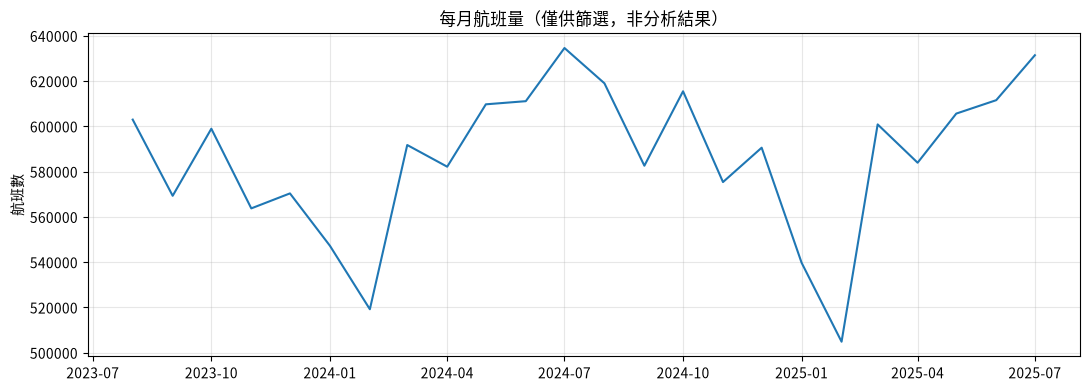

In [8]:
FIGDIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly["ym"], monthly["len"])
ax.set_title("每月航班量（僅供篩選，非分析結果）")
ax.set_ylabel("航班數")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGDIR / "explore_flights_monthly.png", dpi=120)
plt.show()

## 6. 結構可衍生性檢查

這份資料的複雜度不只來自 211 個欄位，也來自單位之間的關係：
機尾號可串接當日航段（追蹤結構），起降機場構成有向網路。

In [9]:
for label, col in (
    ("機尾號（追蹤結構）", "tail_number"),
    ("航空公司", "operating_carrier"),
    ("起點機場", "origin_iata"),
    ("終點機場", "dest_iata"),
):
    if col in cols:
        u = uniq_map.get(col)
        print(f"{label:20s} {col:24s} 唯一值 {u:,}" if isinstance(u, int)
              else f"{label:20s} {col:24s}")

n_routes = lf.select(
    pl.concat_str([pl.col("origin_iata"), pl.col("dest_iata")], separator="-").n_unique()
).collect().item()
print(f"航線（origin-dest 組合）唯一值：{n_routes:,}")

legs = (
    lf.filter(pl.col("tail_number").is_not_null())
    .group_by("tail_number").len().collect()["len"]
)
print(f"每架機尾號的航段數：中位數 {legs.median():,.0f}、"
      f"平均 {legs.mean():,.1f}、最大 {legs.max():,}")

機尾號（追蹤結構）            tail_number              唯一值 6,397
航空公司                 operating_carrier        唯一值 15
起點機場                 origin_iata              唯一值 353
終點機場                 dest_iata                唯一值 353


航線（origin-dest 組合）唯一值：7,201


每架機尾號的航段數：中位數 2,219、平均 2,193.7、最大 6,346


## 7. 延誤分布（單變數）

In [10]:
delay_col = next((c for c in ("arr_delay_min", "dep_delay_min") if c in cols), None)
s = lf.select(pl.col(delay_col)).collect()[delay_col].drop_nulls()

print(f"欄位：{delay_col}")
for q in (0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99):
    print(f"  q{q:>5.2f}  {s.quantile(q):8.1f} 分")

欄位：arr_delay_min
  q 0.01     -37.0 分
  q 0.05     -28.0 分


  q 0.25     -15.0 分


  q 0.50      -6.0 分
  q 0.75       9.0 分
  q 0.90      43.0 分


  q 0.95      83.0 分


  q 0.99     214.0 分


**結果變數強右偏**：中位數接近 0 甚至為負（提早抵達），但 99 分位遠在
高處。正式分析時須考慮轉換或改用適合長尾的模型。

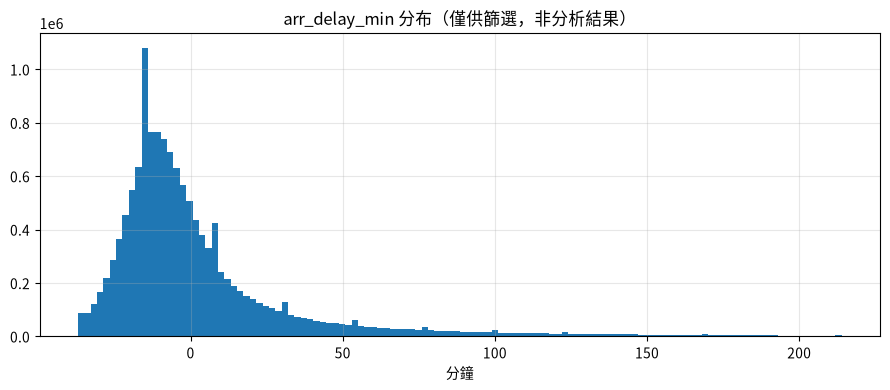

In [11]:
# 長尾極端值會壓扁圖形，截在 1% 與 99% 分位之間看主體形狀。
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(s.filter(s.is_between(s.quantile(0.01), s.quantile(0.99))), bins=120)
ax.set_title(f"{delay_col} 分布（僅供篩選，非分析結果）")
ax.set_xlabel("分鐘")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGDIR / "explore_flights_delay_hist.png", dpi=120)
plt.show()

## 8. 飛航天氣等級的樣本量

此表僅確認各等級樣本量是否足夠，**不構成處理效應估計**。

In [12]:
cat_col = next((c for c in cols if "flight_category" in c or "flight_cat" in c), None)
tab = (
    lf.group_by(cat_col)
    .agg(pl.len().alias("n"), pl.col(delay_col).mean().alias("平均延誤分"))
    .sort("n", descending=True).collect()
)
print(f"分組欄位：{cat_col}")
with pl.Config(tbl_rows=-1):
    print(tab)

分組欄位：wx_origin_flight_category
shape: (5, 3)
┌───────────────────────────┬──────────┬────────────┐
│ wx_origin_flight_category ┆ n        ┆ 平均延誤分 │
│ ---                       ┆ ---      ┆ ---        │
│ str                       ┆ u32      ┆ f64        │
╞═══════════════════════════╪══════════╪════════════╡
│ VFR                       ┆ 11910145 ┆ 6.023853   │
│ MVFR                      ┆ 1293044  ┆ 8.522884   │
│ IFR                       ┆ 492421   ┆ 15.764038  │
│ LIFR                      ┆ 344515   ┆ 17.825528  │
│ null                      ┆ 22504    ┆ 7.658753   │
└───────────────────────────┴──────────┴────────────┘


VFR → MVFR → IFR → LIFR 是目視飛行到儀器飛行的惡化順序。
平均延誤隨天氣惡化**單調上升**，且最差的 LIFR 仍有 34 萬班，
樣本量足夠。

這確認了「實際氣象 vs 自我回報」的落差算得出來。
**僅供篩選，非分析結果。**

## 9. 回報偏誤素材的可用性

這是本候選的核心——`reported_` 欄位是航空公司自報的延誤成因，
要拿它跟實測氣象對照。先確認這些欄位真的有值。

In [13]:
rep_cols = [c for c in cols if c.startswith("reported_")]
print(f"reported_ 欄位共 {len(rep_cols)} 個：\n  {rep_cols}\n")

nonzero = lf.select([
    (pl.col(c) > 0).sum().alias(c) for c in rep_cols if schema[c].is_numeric()
]).collect()
print("各 reported_ 欄位大於零的列數：")
with pl.Config(tbl_cols=-1, tbl_width_chars=200):
    print(nonzero)

reported_ 欄位共 5 個：
  ['reported_carrier_delay_min', 'reported_weather_delay_min', 'reported_nas_delay_min', 'reported_security_delay_min', 'reported_late_aircraft_delay_min']

各 reported_ 欄位大於零的列數：
shape: (1, 5)
┌────────────────────────────┬────────────────────────────┬────────────────────────┬─────────────────────────────┬─────────────────────────────────┐
│ reported_carrier_delay_min ┆ reported_weather_delay_min ┆ reported_nas_delay_min ┆ reported_security_delay_min ┆ reported_late_aircraft_delay_m… │
│ ---                        ┆ ---                        ┆ ---                    ┆ ---                         ┆ ---                             │
│ u32                        ┆ u32                        ┆ u32                    ┆ u32                         ┆ u32                             │
╞════════════════════════════╪════════════════════════════╪════════════════════════╪═════════════════════════════╪═════════════════════════════════╡
│ 1543365                    ┆ 176581      

## 10. 機場對照表

作者說這張表「不存在於任何維護中的公開資料」，是這份資料集的關鍵貢獻，
也是本候選第三問（我們有什麼他們拿不到的）的答案。

In [14]:
if AIRPORTS.exists():
    ar = pl.read_parquet(AIRPORTS)
    print(f"列數 {len(ar):,}、欄數 {ar.width}\n")
    print("全部欄位：")
    for c in ar.columns:
        print(f"  {c}")

    # 完整寬度會爆版，只看對照的關鍵欄位
    key = [c for c in (
        "iata_code", "icao_code", "isd_station_id", "isd_station_name",
        "station_distance_km", "station_match_method", "elevation_delta_m",
    ) if c in ar.columns]
    print("\n對照關鍵欄位（前 8 列）：")
    with pl.Config(tbl_cols=-1, tbl_width_chars=160, fmt_str_lengths=30):
        print(ar.select(key).head(8))

    print("\n比對方法的分布：")
    print(ar.group_by("station_match_method").agg(pl.len().alias("機場數"))
          .sort("機場數", descending=True))

    d = ar["station_distance_km"].drop_nulls()
    print(f"\n機場到測站的距離：中位數 {d.median():.1f} km、"
          f"q90 {d.quantile(0.9):.1f} km、最大 {d.max():.1f} km")

    # 作者自己標出了需要留意的比對
    flags = [c for c in ar.columns if c.startswith("flag_")]
    print("\n作者標記的品質旗標：")
    for f in flags:
        print(f"  {f:34s} {ar[f].sum():>4} 個機場")

列數 386、欄數 35

全部欄位：
  iata_code
  bts_airport_id
  bts_airport_seq_id
  icao_code
  airport_name
  city
  state
  country
  latitude
  longitude
  elevation_m
  iana_timezone
  isd_station_id
  isd_station_id_secondary
  station_changeover_date
  isd_station_name
  isd_station_lat
  isd_station_lon
  station_elev_m
  elevation_delta_m
  station_distance_km
  station_match_method
  match_note
  geo_note
  first_seen_date
  last_seen_date
  total_flights_v1_window
  flag_distance_gt_10km
  flag_non_callsign_match
  flag_elevation_delta
  flag_timezone_special
  flag_station_continuation
  station_has_2019_file
  station_has_2022_file
  station_has_2025_file

對照關鍵欄位（前 8 列）：
shape: (8, 7)
┌───────────┬───────────┬────────────────┬─────────────────────────────────┬─────────────────────┬──────────────────────┬───────────────────┐
│ iata_code ┆ icao_code ┆ isd_station_id ┆ isd_station_name                ┆ station_distance_km ┆ station_match_method ┆ elevation_delta_m │
│ ---       ┆ ---     

## 小結

- 欄位前綴系統把洩漏風險寫進命名，實測確認三組前綴各有 106／54／5 欄
- 缺失以結構性為主，氣象缺值以 `obs_missing` 標記且不插補
- 結構可衍生：機尾號追蹤、機場網路、航線組合皆可建構
- 天氣等級的樣本量足夠，延誤隨天氣惡化單調上升
- `reported_` 欄位有值，回報偏誤的對照做得起來
- 機場對測站的對照表存在，這是第三問的答案

**以上全部為篩選用檢視，非分析結果。**